## Prawo Ohma

In [2]:
import os
import numpy as np
from PyLTSpice import SimCommander
from PyLTSpice import RawRead
import matplotlib.pyplot as plt
import pandas as pd


BASE_DIR = "E:\\X\\Programming_Workspace\\Python_Workspace\\LTSpice_Python_Automation\\Elektronika_Analogowa_AGH\\Wzmacniacze\\"
# === KONFIGURACJA ===
asc_file = BASE_DIR + "wzmacniacze\\wtornik.asc"
ltspice_path = "C:\\Users\\mateu\\AppData\\Local\\Programs\\ADI\\LTspice\\XVIIx64.exe"

# Debugging output
print(f"ASC File Path: {asc_file}")
print(f"LTspice Path: {ltspice_path}")

# === UTWORZENIE OBIEKTU SYMULACJI ===
sim = SimCommander(asc_file)
sim.add_instructions(".ac dec 100 100000 10000000")
# === URUCHOMIENIE SYMULACJI ===
print("Uruchamiam symulację...")
sim.run()

# === SPRAWDZENIE PLIKU .RAW ===
# The .raw file is generated in the same directory as the .asc file
raw_file_path = os.path.splitext(asc_file)[0] + "_1.raw"
print(f"Sprawdzam plik .raw: {raw_file_path}")
# if not os.path.exists(raw_file_path):
#     raise RuntimeError(f"Plik .raw nie został wygenerowany: {raw_file_path}")

# === WYNIKI ===
raw = RawRead(raw_file_path)
signals = raw.get_trace_names()
print("Dostępne sygnały:", signals)

del sim


ASC File Path: E:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Wzmacniacze\wzmacniacze\wtornik.asc
LTspice Path: C:\Users\mateu\AppData\Local\Programs\ADI\LTspice\XVIIx64.exe
Uruchamiam symulację...
Sprawdzam plik .raw: E:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Wzmacniacze\wzmacniacze\wtornik_1.raw
Dostępne sygnały: ['frequency', 'V(out)', 'V(v-)', 'V(in)', 'V(v+)', 'I(V1)', 'I(V2)', 'I(V3)', 'Ix(xu1:1)', 'Ix(xu1:2)', 'Ix(xu1:3)', 'Ix(xu1:4)', 'Ix(xu1:5)']


e:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\.venv\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
e:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\.venv\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


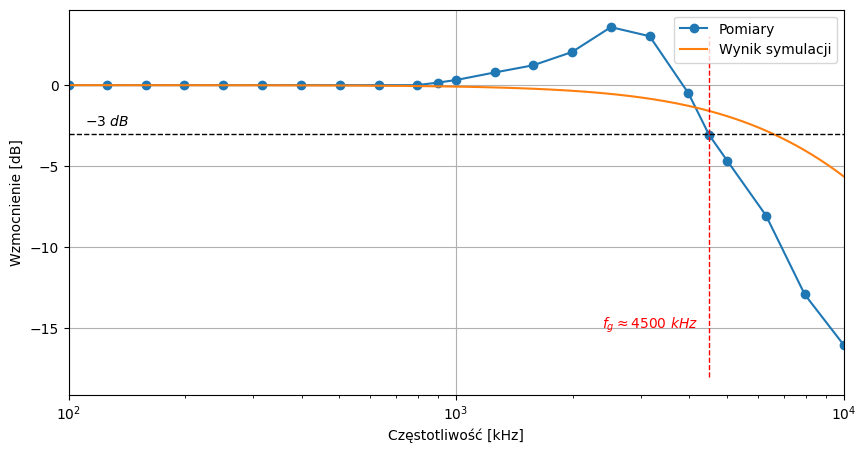

In [29]:
freq = raw.get_trace("frequency").get_wave()/1000
v_in = raw.get_trace("V(in)").get_wave()
v_out = raw.get_trace("V(out)").get_wave()
G = 20 *np.log10(np.abs(v_out/ v_in))

data = pd.read_csv(BASE_DIR + "csv\\wtornik.csv")
freq_zmierzone = data["frequency"].values
G_zmierzone = data["G"].values
# === RYSUJEMY WYKRES ===

fig,ax = plt.subplots(figsize=(10, 5))
ax.semilogx(freq_zmierzone, G_zmierzone, label=f"Pomiary", linestyle="-", marker="o")
ax.semilogx(freq, G, label=f"Wynik symulacji")

ax.set_xlabel("Częstotliwość [kHz]")
ax.set_ylabel("Wzmocnienie [dB]")
# ax.set_title("Układ wzmacniacza o wzmocnieniu jednostkowym")
ax.grid(True)
ax.legend()
ax.plot(freq,-3*np.ones(freq.shape) ,color='black', linestyle='--', linewidth=1)
ax.text(freq_zmierzone[1], -2.5, f"$-3 \ dB$", color='black', fontsize=10, ha='center')
ax.vlines(freq_zmierzone[-5],-18,3, color='red', linestyle='--', linewidth=1)
ax.text(freq_zmierzone[-7], -15, f"$f_g \\approx {freq_zmierzone[-5]} \ kHz$", color='red', fontsize=10, ha='center')
ax.set_xlim(100, 1e4)
fig.savefig("wtornik.png")


## Wzmacniacz nieodrwacajacy

In [30]:

asc_file = BASE_DIR + "wzmacniacze\\wzmacniacz_nieodwracajacy.asc"

# Debugging output
print(f"ASC File Path: {asc_file}")
print(f"LTspice Path: {ltspice_path}")

# === UTWORZENIE OBIEKTU SYMULACJI ===
sim = SimCommander(asc_file)
sim.add_instructions(".ac dec 100 100000 10000000")
# === URUCHOMIENIE SYMULACJI ===
print("Uruchamiam symulację...")
sim.run()

# === SPRAWDZENIE PLIKU .RAW ===
# The .raw file is generated in the same directory as the .asc file
raw_file_path = os.path.splitext(asc_file)[0] + "_1.raw"
print(f"Sprawdzam plik .raw: {raw_file_path}")
# if not os.path.exists(raw_file_path):
#     raise RuntimeError(f"Plik .raw nie został wygenerowany: {raw_file_path}")

# === WYNIKI ===
raw = RawRead(raw_file_path)
signals = raw.get_trace_names()
print("Dostępne sygnały:", signals)

del sim

ASC File Path: E:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Wzmacniacze\wzmacniacze\wzmacniacz_nieodwracajacy.asc
LTspice Path: C:\Users\mateu\AppData\Local\Programs\ADI\LTspice\XVIIx64.exe
Uruchamiam symulację...
Sprawdzam plik .raw: E:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Wzmacniacze\wzmacniacze\wzmacniacz_nieodwracajacy_1.raw
Dostępne sygnały: ['frequency', 'V(n001)', 'V(v-)', 'V(out)', 'V(in)', 'V(v+)', 'I(V1)', 'I(V2)', 'I(R1)', 'I(R2)', 'I(V3)', 'Ix(xu1:1)', 'Ix(xu1:2)', 'Ix(xu1:3)', 'Ix(xu1:4)', 'Ix(xu1:5)']


e:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\.venv\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
e:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\.venv\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


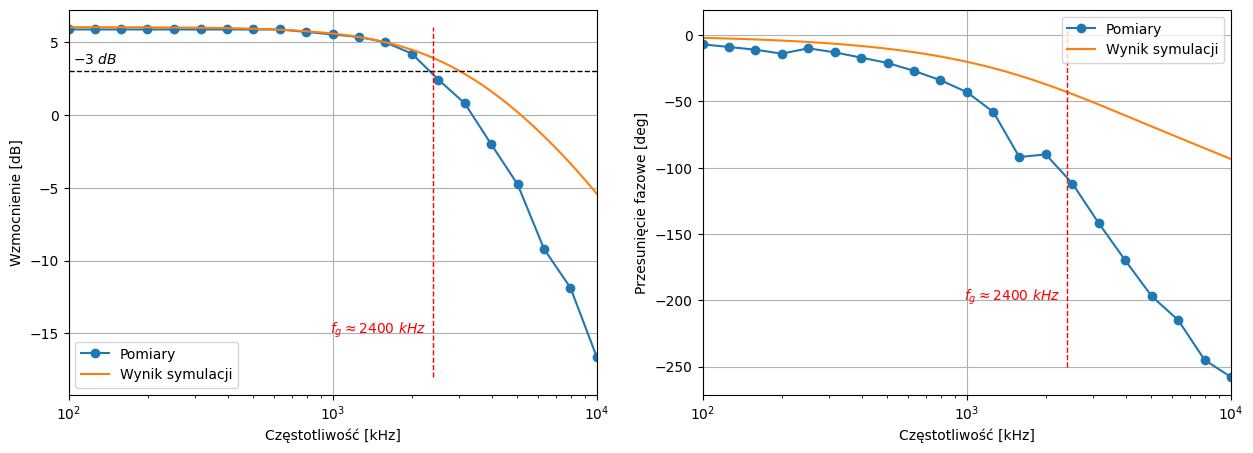

In [47]:
freq = raw.get_trace("frequency").get_wave()/1000
v_in = raw.get_trace("V(in)").get_wave()
v_out = raw.get_trace("V(out)").get_wave()
G = 20 *np.log10(np.abs(v_out/ v_in))
phase = np.angle(v_out/v_in, deg=True)

data = pd.read_csv(BASE_DIR + "csv\\nieodwracajacy.csv")
freq_zmierzone = data["frequency"].values
G_zmierzone = data["G"].values
phase_zmierzone = -data["deg"].values
# === RYSUJEMY WYKRES ===

fig,ax = plt.subplots(nrows=1, ncols = 2, figsize=(15, 5))
# fig.suptitle("Układ wzmacniacza nieodwracającego fazy")

ax[0].semilogx(freq_zmierzone, G_zmierzone, label=f"Pomiary", linestyle="-", marker="o")
ax[0].semilogx(freq, G, label=f"Wynik symulacji")


ax[0].set_xlabel("Częstotliwość [kHz]")
ax[0].set_ylabel("Wzmocnienie [dB]")
# ax[0].set_title("Układ wzmacniacza o wzmocnieniu jednostkowym")
ax[0].grid(True)
ax[0].legend()

ax[1].semilogx(freq_zmierzone, phase_zmierzone, label=f"Pomiary", linestyle="-", marker="o")
ax[1].semilogx(freq, phase, label=f"Wynik symulacji")


ax[1].set_xlabel("Częstotliwość [kHz]")
ax[1].set_ylabel("Przesunięcie fazowe [deg]")
# ax[1].set_title("Układ wzmacniacza o wzmocnieniu jednostkowym")
ax[1].grid(True)
ax[1].legend()

ax[0].plot(freq,(G[0]-3)*np.ones(freq.shape) ,color='black', linestyle='--', linewidth=1)
ax[0].text(freq_zmierzone[1], G[0]-2.5, f"$-3 \ dB$", color='black', fontsize=10, ha='center')
ax[0].vlines(2400,-18,6, color='red', linestyle='--', linewidth=1)
ax[0].text(freq_zmierzone[-9]-100, -15, f"$f_g \\approx {2400} \ kHz$", color='red', fontsize=10, ha='center')
ax[0].set_xlim(100, 1e4)

ax[1].vlines(2400,-250,6, color='red', linestyle='--', linewidth=1)
ax[1].text(freq_zmierzone[-9]-100, -200, f"$f_g \\approx {2400} \ kHz$", color='red', fontsize=10, ha='center')
ax[1].set_xlim(100, 1e4)

fig.savefig("nieodwracajcy.png")


## Odwracajacy

In [58]:

asc_file = BASE_DIR + "wzmacniacze\\wzmacniacz_odwracajacy.asc"

# Debugging output
print(f"ASC File Path: {asc_file}")
print(f"LTspice Path: {ltspice_path}")

# === UTWORZENIE OBIEKTU SYMULACJI ===
sim = SimCommander(asc_file)
sim.add_instructions(".ac dec 100 100000 10000000")
# === URUCHOMIENIE SYMULACJI ===
print("Uruchamiam symulację...")
sim.run()

# === SPRAWDZENIE PLIKU .RAW ===
# The .raw file is generated in the same directory as the .asc file
raw_file_path = os.path.splitext(asc_file)[0] + "_1.raw"
print(f"Sprawdzam plik .raw: {raw_file_path}")
# if not os.path.exists(raw_file_path):
#     raise RuntimeError(f"Plik .raw nie został wygenerowany: {raw_file_path}")

# === WYNIKI ===
raw = RawRead(raw_file_path)
signals = raw.get_trace_names()
print("Dostępne sygnały:", signals)

del sim 

ASC File Path: E:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Wzmacniacze\wzmacniacze\wzmacniacz_odwracajacy.asc
LTspice Path: C:\Users\mateu\AppData\Local\Programs\ADI\LTspice\XVIIx64.exe
Uruchamiam symulację...
Sprawdzam plik .raw: E:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Wzmacniacze\wzmacniacze\wzmacniacz_odwracajacy_1.raw
Dostępne sygnały: ['frequency', 'V(v+)', 'V(out)', 'V(in)', 'V(n001)', 'V(v-)', 'I(V1)', 'I(R2)', 'I(V2)', 'I(R1)', 'I(V3)', 'Ix(xu1:1)', 'Ix(xu1:2)', 'Ix(xu1:3)', 'Ix(xu1:4)', 'Ix(xu1:5)']


e:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\.venv\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
e:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\.venv\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


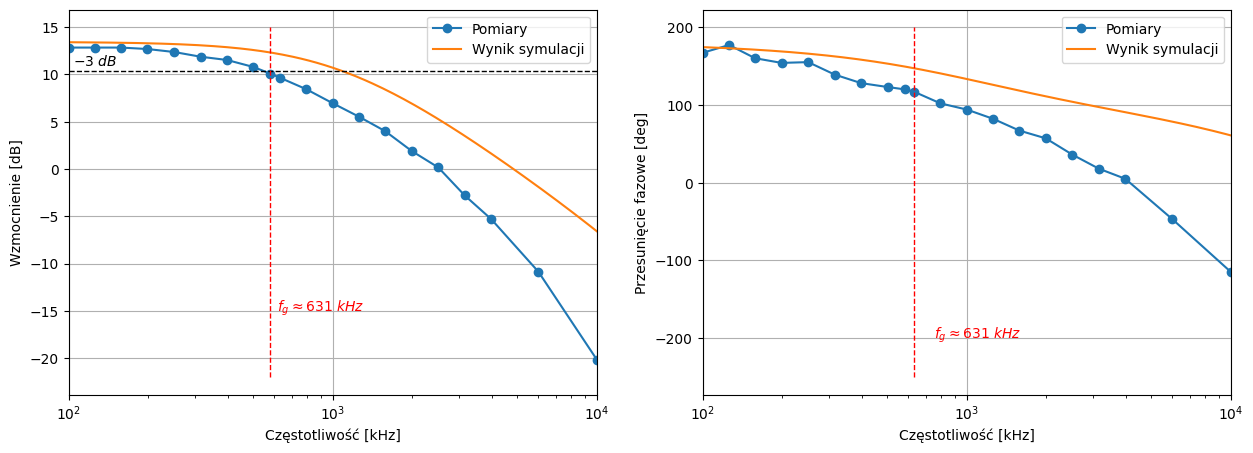

In [66]:
freq = raw.get_trace("frequency").get_wave()/1000
v_in = raw.get_trace("V(in)").get_wave()
v_out = raw.get_trace("V(out)").get_wave()
G = 20 *np.log10(np.abs(v_out/ v_in))
phase = np.angle(v_out/v_in, deg=True)

data = pd.read_csv(BASE_DIR + "csv\\odwracajacy.csv")
freq_zmierzone = data["frequency"].values
G_zmierzone = data["G"].values
phase_zmierzone = data["deg"].values
phase_zmierzone = np.where(phase_zmierzone > 180, 360 -phase_zmierzone , phase_zmierzone)
# phase_zmierzone = 360 - phase_zmierzone
# === RYSUJEMY WYKRES ===

fig,ax = plt.subplots(nrows=1, ncols = 2, figsize=(15, 5))
# fig.suptitle("Układ wzmacniacza odwracającego fazę")

ax[0].semilogx(freq_zmierzone, G_zmierzone, label=f"Pomiary", linestyle="-", marker="o")
ax[0].semilogx(freq, G, label=f"Wynik symulacji")


ax[0].set_xlabel("Częstotliwość [kHz]")
ax[0].set_ylabel("Wzmocnienie [dB]")
# ax[0].set_title("Układ wzmacniacza o wzmocnieniu jednostkowym")
ax[0].grid(True)
ax[0].legend()

ax[1].semilogx(freq_zmierzone, phase_zmierzone, label=f"Pomiary", linestyle="-", marker="o")
ax[1].semilogx(freq, phase, label=f"Wynik symulacji")


ax[1].set_xlabel("Częstotliwość [kHz]")
ax[1].set_ylabel("Przesunięcie fazowe [deg]")
# ax[1].set_title("Układ wzmacniacza o wzmocnieniu jednostkowym"
ax[1].grid(True)
ax[1].legend()


ax[0].plot(freq,(G[0]-3)*np.ones(freq.shape) ,color='black', linestyle='--', linewidth=1)
ax[0].text(freq_zmierzone[1], G[0]-2.5, f"$-3 \ dB$", color='black', fontsize=10, ha='center')
ax[0].vlines(freq_zmierzone[8],-22,15, color='red', linestyle='--', linewidth=1)
ax[0].text(freq_zmierzone[-9]-100, -15, f"$f_g \\approx {freq_zmierzone[9]} \ kHz$", color='red', fontsize=10, ha='center')
ax[0].set_xlim(100, 1e4)

ax[1].vlines(freq_zmierzone[9],-250,200, color='red', linestyle='--', linewidth=1)
ax[1].text(freq_zmierzone[-9]+100, -200, f"$f_g \\approx {freq_zmierzone[9]} \ kHz$", color='red', fontsize=10, ha='center')
ax[1].set_xlim(100, 1e4)


fig.savefig("chka_odwracajcy.png")


## Charakterystyka przejsciwoa wzmacniacz odwracajacy

In [151]:

asc_file = BASE_DIR + "wzmacniacze\\wzmacniacz_odwracajacy.asc"

# Debugging output
print(f"ASC File Path: {asc_file}")
print(f"LTspice Path: {ltspice_path}")

# === UTWORZENIE OBIEKTU SYMULACJI ===
sim = SimCommander(asc_file)
sim.add_instructions(".dc V3 -6 6 0.1")
# === URUCHOMIENIE SYMULACJI ===
print("Uruchamiam symulację...")
sim.run()

# === SPRAWDZENIE PLIKU .RAW ===
# The .raw file is generated in the same directory as the .asc file
raw_file_path = os.path.splitext(asc_file)[0] + "_1.raw"
print(f"Sprawdzam plik .raw: {raw_file_path}")
# if not os.path.exists(raw_file_path):
#     raise RuntimeError(f"Plik .raw nie został wygenerowany: {raw_file_path}")

# === WYNIKI ===
raw = RawRead(raw_file_path)
signals = raw.get_trace_names()
print("Dostępne sygnały:", signals)

del sim 

ASC File Path: E:\X\Programming_Workspace\Jupyter_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Wzmacniacze\wzmacniacze\wzmacniacz_odwracajacy.asc
LTspice Path: C:\Users\mateu\AppData\Local\Programs\ADI\LTspice\XVIIx64.exe
Uruchamiam symulację...
Sprawdzam plik .raw: E:\X\Programming_Workspace\Jupyter_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Wzmacniacze\wzmacniacze\wzmacniacz_odwracajacy_1.raw
Dostępne sygnały: ['V3', 'V(v+)', 'V(out)', 'V(in)', 'V(n001)', 'V(v-)', 'I(V1)', 'I(R2)', 'I(V2)', 'I(R1)', 'I(V3)', 'Ix(xu1:1)', 'Ix(xu1:2)', 'Ix(xu1:3)', 'Ix(xu1:4)', 'Ix(xu1:5)']


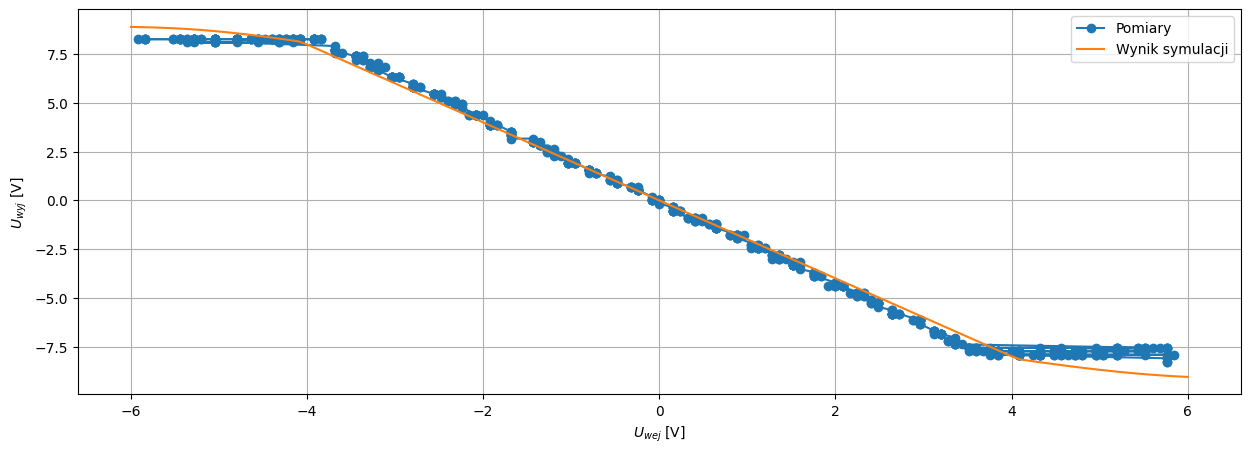

In [152]:
v_in = raw.get_trace("V(in)").get_wave()
v_out = raw.get_trace("V(out)").get_wave()
data = pd.read_csv(BASE_DIR + "csv\\charakterystyka_przejsciowa_wzmacniacz_odwrac.csv", )
data = data.sort_values(by="OUT")
wej = data["IN"].values
wyj = data["OUT"].values
# === RYSUJEMY WYKRES ===

fig,ax = plt.subplots(figsize=(15, 5))
# fig.suptitle("Charakterystyka przejściowa wzmacniacza odwracającego fazę")

ax.plot(wej, wyj, label=f"Pomiary", linestyle="-", marker="o")
ax.plot(v_in, v_out, label=f"Wynik symulacji")


ax.set_xlabel("$U_{wej}$ [V]")
ax.set_ylabel("$U_{wyj}$ [V]")
# ax.set_title("Układ wzmacniacza o wzmocnieniu jednostkowym")
ax.grid(True)
ax.legend()



fig.savefig("odwracajcy_przejsciowa.png")


In [155]:
## Superdioda

asc_file = BASE_DIR + "wzmacniacze\\super_dioda.asc"

# Debugging output
print(f"ASC File Path: {asc_file}")
print(f"LTspice Path: {ltspice_path}")

# === UTWORZENIE OBIEKTU SYMULACJI ===
sim = SimCommander(asc_file)
sim.add_instructions(".dc V3 -6 6 0.1")
# === URUCHOMIENIE SYMULACJI ===
print("Uruchamiam symulację...")
sim.run()

# === SPRAWDZENIE PLIKU .RAW ===
# The .raw file is generated in the same directory as the .asc file
raw_file_path = os.path.splitext(asc_file)[0] + "_1.raw"
print(f"Sprawdzam plik .raw: {raw_file_path}")
# if not os.path.exists(raw_file_path):
#     raise RuntimeError(f"Plik .raw nie został wygenerowany: {raw_file_path}")

# === WYNIKI ===
raw = RawRead(raw_file_path)
signals = raw.get_trace_names()
print("Dostępne sygnały:", signals)

del sim 

ASC File Path: E:\X\Programming_Workspace\Jupyter_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Wzmacniacze\wzmacniacze\super_dioda.asc
LTspice Path: C:\Users\mateu\AppData\Local\Programs\ADI\LTspice\XVIIx64.exe
Uruchamiam symulację...
Sprawdzam plik .raw: E:\X\Programming_Workspace\Jupyter_Workspace\LTSpice_Python_Automation\Elektronika_Analogowa_AGH\Wzmacniacze\wzmacniacze\super_dioda_1.raw
Dostępne sygnały: ['V3', 'V(n001)', 'V(v-)', 'V(n002)', 'V(out)', 'V(n003)', 'V(v+)', 'V(in)', 'I(V1)', 'I(R2)', 'I(V2)', 'I(V3)', 'I(R3)', 'I(R1)', 'I(D1)', 'I(D2)', 'Ix(xu1:1)', 'Ix(xu1:2)', 'Ix(xu1:3)', 'Ix(xu1:4)', 'Ix(xu1:5)']


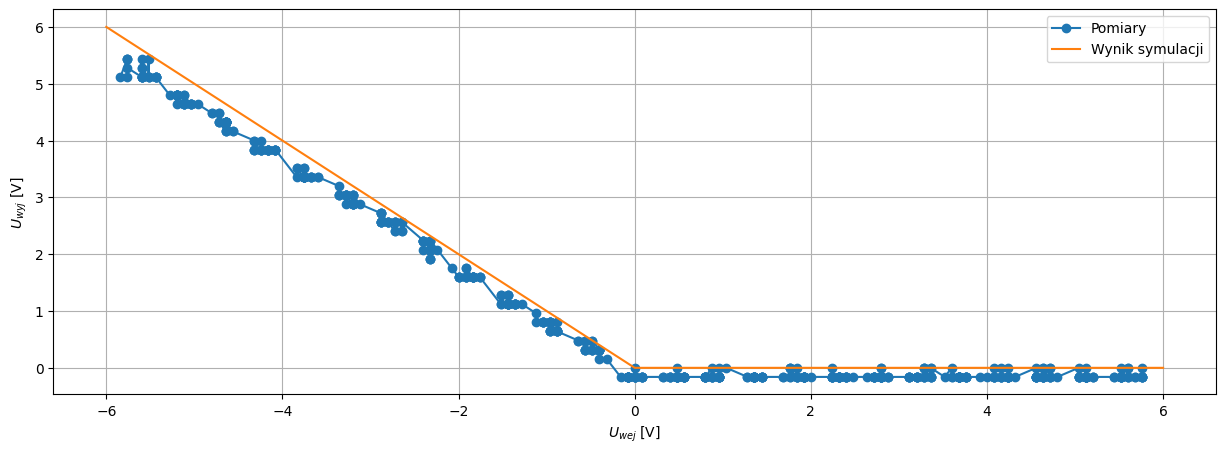

In [156]:
v_in = raw.get_trace("V(in)").get_wave()
v_out = raw.get_trace("V(out)").get_wave()
data = pd.read_csv(BASE_DIR + "csv\\super_dioda.csv" )
data = data.sort_values(by="CH1")
wej = data["CH1"].values
wyj = data["CH2"].values * 2
# === RYSUJEMY WYKRES ===

fig,ax = plt.subplots(figsize=(15, 5))
# fig.suptitle("Charakterystyka przejściowa układu super diody")

ax.plot(wej, wyj, label=f"Pomiary", linestyle="-", marker="o")
ax.plot(v_in, v_out, label=f"Wynik symulacji")


ax.set_xlabel("$U_{wej}$ [V]")
ax.set_ylabel("$U_{wyj}$ [V]")
# ax.set_title("Układ wzmacniacza o wzmocnieniu jednostkowym")
ax.grid(True)
ax.legend()



fig.savefig("super_dioda.png")
